In [188]:
using LinearAlgebra
using DifferentialEquations, Plots
using BenchmarkTools
using HypothesisTests
default(grid=false,legend=false, size=(400,320), dpi=300, tickfontsize=16, lw=2, lc=:gray, labelfontsize=16, tickdir=:out, fontfamily="Arial", legendfontsize=13, markercolor=:indianred)


mydir = "../helper/"
include(mydir * "base.jl")
include(mydir * "optimization.jl")
include(mydir * "misc.jl")

annotate_exp_traj (generic function with 2 methods)

### Load data

In [2]:
using DelimitedFiles
# INSERT YOUR OWN DATA DIRECTORY AND FILENAME HERE
# E. coli MG1655 (CGSC 6300)/20090131/xy01c1/ch1_cell0.dat
# data_dir = "../data/xy01c1/"
data_dir = "/Users/shijiezhang/Dropbox (MIT)/stochastic_learning/complete data Curr Biol 20, 1099-1103 (2010)/E. coli MG1655 (CGSC 6300)/20090131/xy01c1/"
filename_all = readdir(data_dir);
DT = 0.01;
DL = 0.05;

In [4]:
select_filename = Vector{String}(undef, 8)
select_filename[1] = "ch0_cell0.dat"
select_filename[2] = "ch1_cell0.dat"
select_filename[3] = "ch1_cell1.dat"
select_filename[4] = "ch2_cell0.dat"
select_filename[5] = "ch3_cell0.dat"
select_filename[6] = "ch4_cell0.dat"
select_filename[7] = "ch5_cell0.dat"
select_filename[8] = "ch6_cell0.dat"

select_time_all = Vector{Vector{Tuple{Float64, Float64}}}(undef, length(select_filename))
select_time_all[1] = [(0.0, 6.8), (7.5, 16.1), (20.0, 28.0), (32.0, 36.5)]
select_time_all[2] = [(0.0, 12.5), (13.5, 20.6)] 
select_time_all[3] = [(3.5, 12.4)] 
select_time_all[4] = [(0., 14.5), (16.0,27.5)]
select_time_all[5] = [(31.2, 38.5)] 
select_time_all[6] = [(35., 38.7)] 
select_time_all[7] = [(30.9, 38.5)]
select_time_all[8] = [(32., 40.)] 

# annotate
Lobs_ = []
tobs_ = []
for idx in eachindex(select_filename)
    tab = readdlm(data_dir * select_filename[idx]);
    varnames = convert(Vector{String}, tab[1,:]);
    tobs = tab[2:end,findfirst(varnames .== "index")] * DT;
    Lobs = tab[2:end,findfirst(varnames .== "length")] * DL;
    Lobs_idx, tobs_idx = filter_exp_traj(Lobs, tobs; select_time = select_time_all[idx] );
    Lobs_ = vcat(Lobs_, Lobs_idx)
    tobs_ = vcat(tobs_, tobs_idx)
end
Lobs_ = convert.(Vector{Float64}, Lobs_);
tobs_ = convert.(Vector{Float64}, tobs_);


In [5]:
isdiv_, dtobs_ = annotate_exp_traj(Lobs_, tobs_);

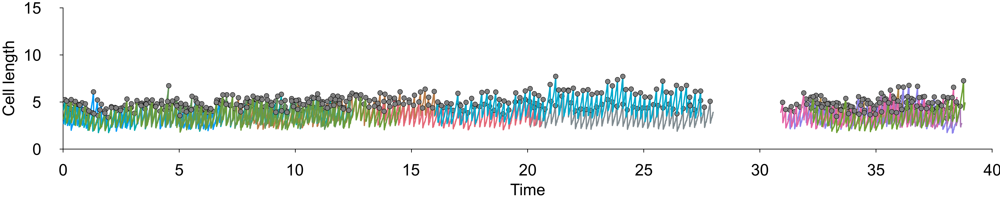

In [6]:
p_traj_obs = plot(; size=(1500,300), xlim=(0,40), ylim=(0,15), xtick=collect(0:5:40), ytick=collect(0:5:15), bottommargin=12Plots.mm,  leftmargin=9Plots.mm, xlabel="Time", ylabel="Cell length")
linecolor_ = palette(:default, length(Lobs_) )
for i in eachindex(Lobs_)
    plot!(p_traj_obs, tobs_[i], Lobs_[i], lc=linecolor_[i])
    scatter!(p_traj_obs, tobs_[i][isdiv_[i]], Lobs_[i][isdiv_[i]], markercolor=:gray)
end
p_traj_obs

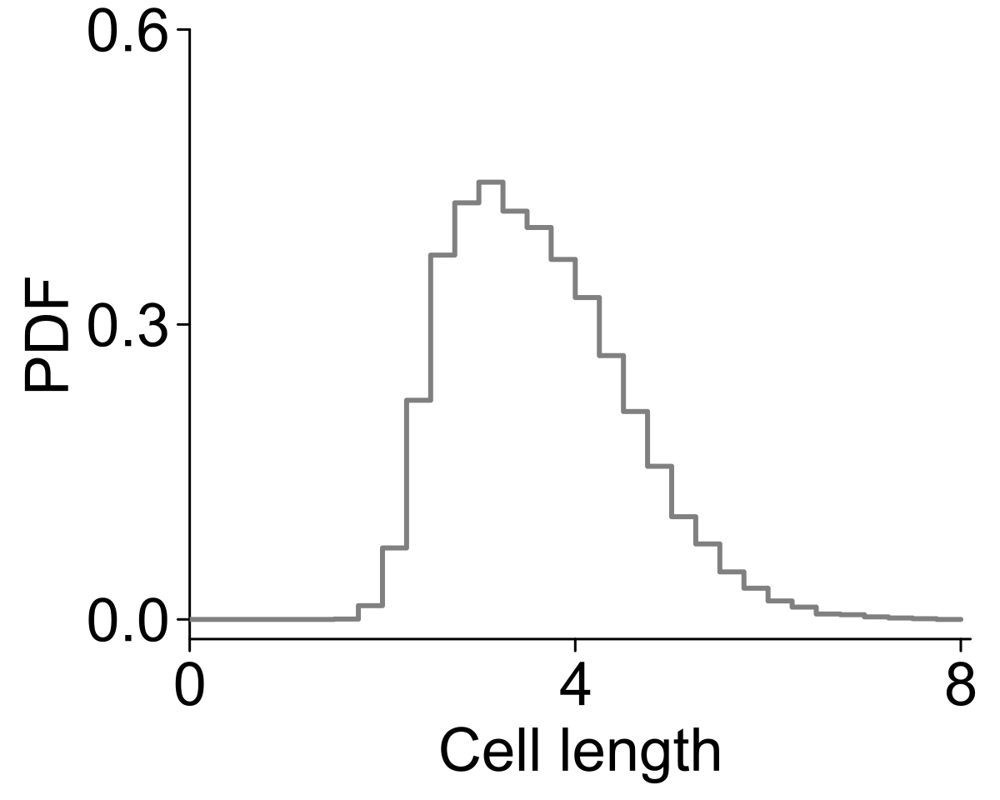

In [7]:
p1 = plot(;xlim=(0,8.1), xtick=[0,4,8],ylim=(-0.02,0.6),ytick=[0,0.3,0.6])
stephist!( p1, vcat(Lobs_...), bins=collect(0:0.25:8), normalize=:pdf, xlabel="Cell length", ylabel="PDF")


### Inference

In [8]:
# basis_func = Polynomial();

n_func = 11;
Θ, Σ = gen_ortho_bases(vcat(Lobs_...), n_func-1);
Θdiv = Θ[vcat(isdiv_...),:];
Θdiv = sum(Θdiv, dims=1)[:];

_, coeffs_sparse = sparse_optimization(Θ, Θdiv, vcat(dtobs_...); EPSILON=1E-7, MAX_ITERS=40);

itr=1: -806.2976708195274


itr=2: -806.3385943369261


itr=3: -805.8106504340406


itr=4: -806.0645472412025


itr=5: -805.8690407085472


itr=6: -805.5576699340681


... (15 outputs left out)

itr=22: -804.1551770452323


itr=23: -804.1550247013931


itr=24: -804.1548509801871


itr=25: -804.1548296499133


In [9]:
display(coeffs_sparse)

11-element Vector{Float64}:
 -0.6784479981277471
  2.614805110603821
 -0.8169272550782014
  3.960047111752422e-92
  0.148122390177299
 -5.252903131730262e-88
 -0.0345644332876002
  3.7711756857401253e-66
 -3.581707778706413e-106
 -2.001428868151845e-110
 -2.7963098747647004e-102

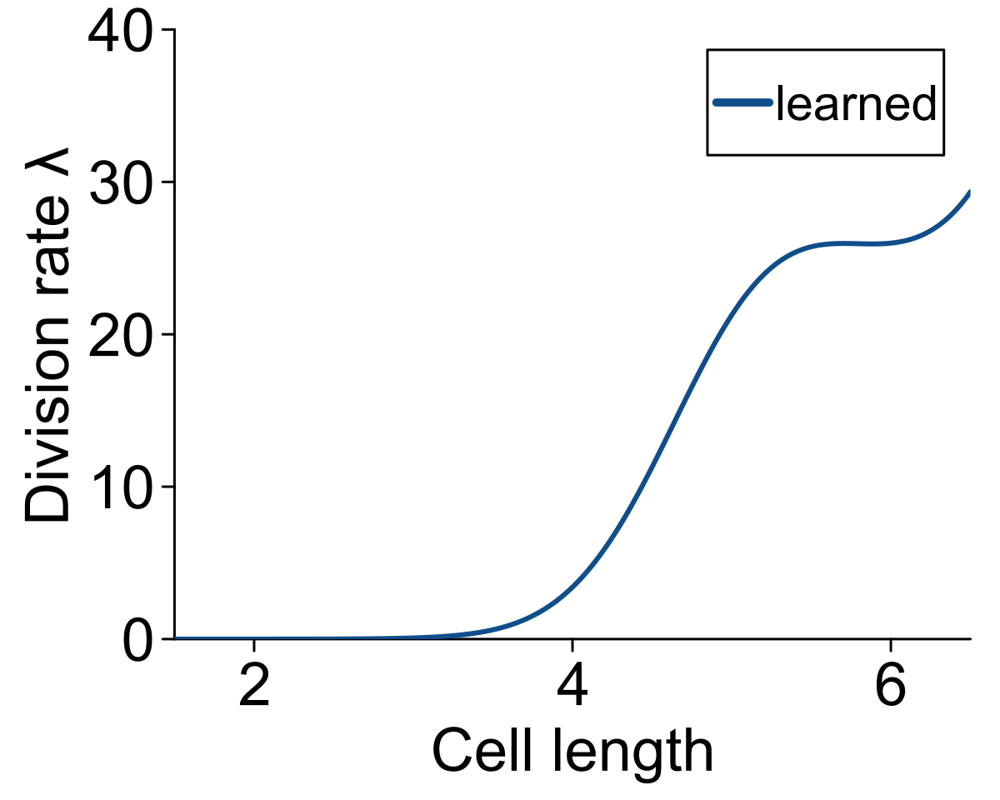

In [10]:
# (optional)
COEFF_TRESHOLD = 0.02
coeffs_sparse[abs.(coeffs_sparse) .< COEFF_TRESHOLD] .= 0.0
# coeffs_dense[abs.(coeffs_dense) .< COEFF_TRESHOLD] .= 0.0;

uu = collect(1.5:0.01:10.5);
logλ_sparse = rec_ortho_bases(uu, Σ, coeffs_sparse);

p2 = plot(;legend=true, ylim=(0,40), ytick=collect(0:10:40), xlim=(1.5, 6.5), xtick=collect(2:2:10))
plot!(p2, uu, exp.(logλ_sparse),label="learned", lw=2, lc=:dodgerblue4,  ylabel="Division rate λ", xlabel="Cell length")


In [11]:
# function filldiagonal!(A::Matrix{T}, val::T; n=size(A,1)) where T
#     for k = 1:n
#         A[k,k] = val
#     end
#     nothing
# end

In [12]:
bf_f = Polynomial()
Y_f = vcat( [ (Lobs_[i][2:end] .- Lobs_[i][1:end-1]) ./ (tobs_[i][2:end] .- tobs_[i][1:end-1])  for i in eachindex(Lobs_)]... );
Lt_f =  vcat( [Lobs_[i][1:end-1] for i in eachindex(Lobs_) ]... );
Lt_f = Lt_f[Y_f .> 0.0]; Y_f = Y_f[Y_f .> 0.0];
Theta_f = gen_bases( Lt_f,  1);

In [13]:
_, coeffs_f = sparse_bayesian_optimization(Theta_f, Y_f)
# coeffs_f[abs.(coeffs_f) .< COEFF_TRESHOLD] .= 0.0

(2.189780106823972, [0.28840407978364463, 3.34313503663326])

In [14]:
coeffs_f

2-element Vector{Float64}:
 0.28840407978364463
 3.34313503663326

In [15]:
# coeffs_f = Theta_f \ Y_f

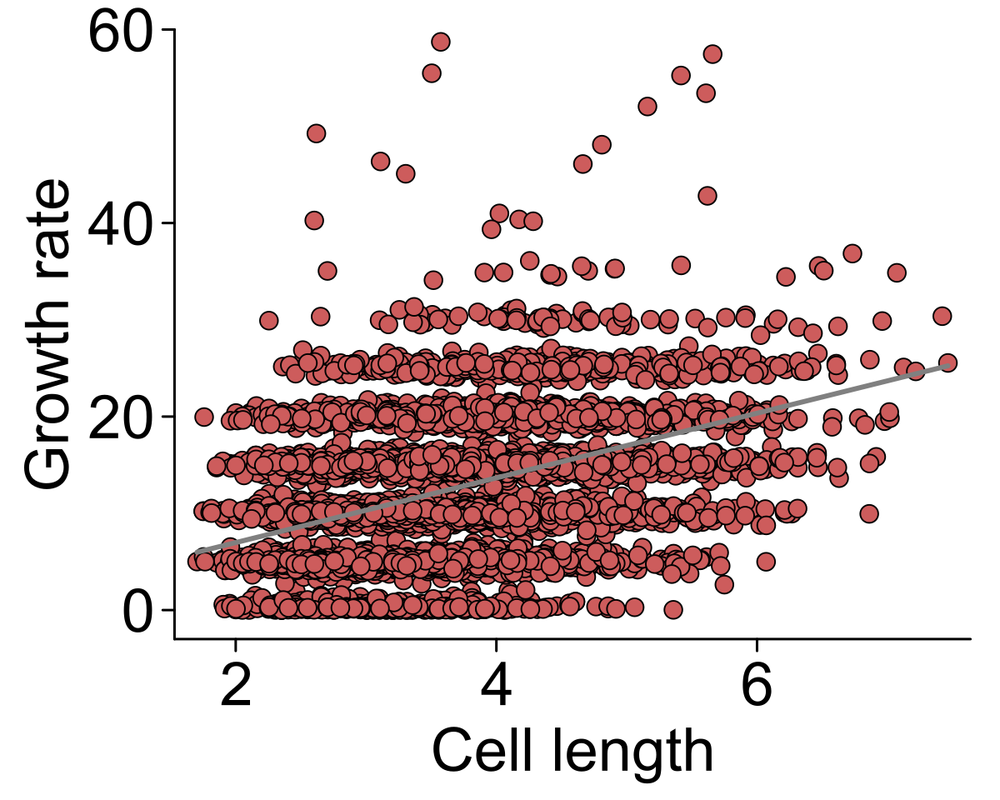

In [16]:
scatter(Lt_f, Y_f, xlabel="Cell length", ylabel="Growth rate", xtick=collect(2:2:10), ytick=(0:20:60), ylim=[-3,60])
plot!(Lt_f, coeffs_f[1] .+ coeffs_f[2]*Lt_f )

In [17]:
bf_g = Polynomial()
Y_g = vcat( [Lobs_[i][isdiv_[i]] .- Lobs_[i][findall(isdiv_[i]) .+  1]  for i in eachindex(Lobs_)]... );
Theta_g = gen_bases( vcat( [Lobs_[i][isdiv_[i]] for i in eachindex(Lobs_) ]... ), 2);

In [18]:
_, coeffs_g = sparse_bayesian_optimization(Theta_g, Y_g)
coeffs_g[abs.(coeffs_g) .< COEFF_TRESHOLD] .= 0.0

2-element view(::Vector{Float64}, [1, 3]) with eltype Float64:
 0.0
 0.0

In [19]:
coeffs_g

3-element Vector{Float64}:
 0.0
 0.5101583895644825
 0.0

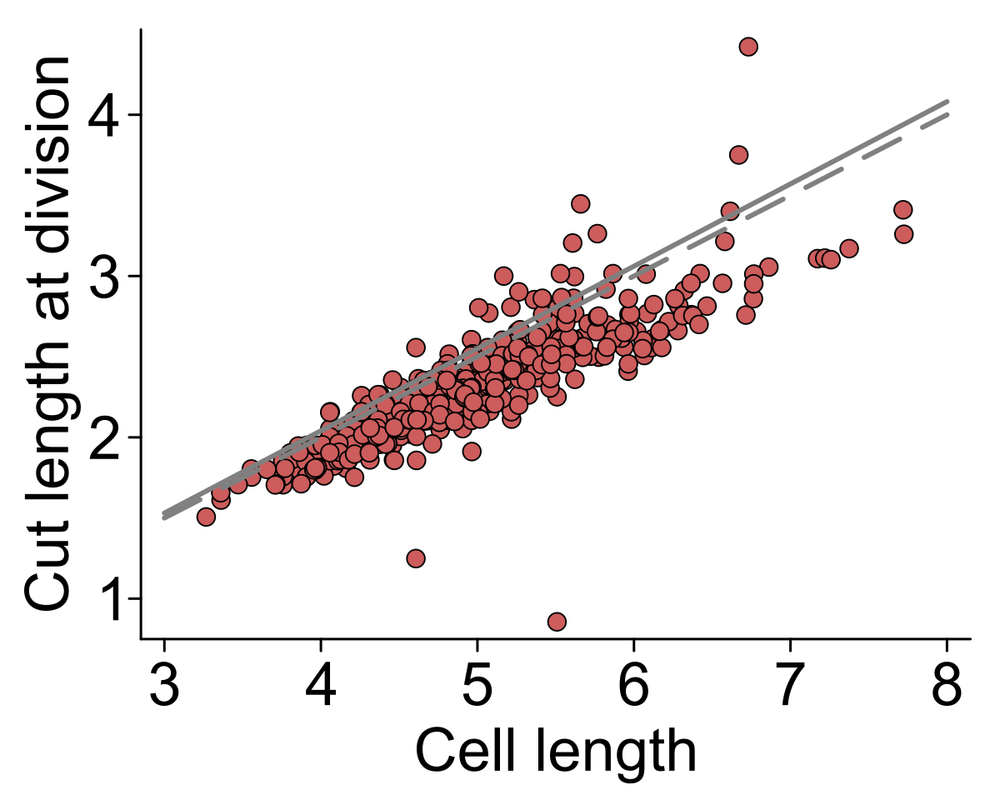

In [20]:
scatter( vcat( [Lobs_[i][isdiv_[i]] for i in eachindex(Lobs_) ]... ), Y_g, xlabel="Cell length", ylabel="Cut length at division")
plot!(collect(3:0.01:8), coeffs_g[1] .+ coeffs_g[2] * collect(3:0.01:8).^1 .+ coeffs_g[3] * collect(3:0.01:8).^2)
plot!(collect(3:0.01:8), 0.5 * collect(3:0.01:8).^1, ls=:dash)


In [21]:
# DE parameters should be 
# (bf_f, coeffs_f, bf_g, coeffs_g, bf_λ, Σ_λ, coeffs_λ)

In [22]:
coeffs_g

3-element Vector{Float64}:
 0.0
 0.5101583895644825
 0.0

In [23]:
function f(du, u, p, t)
    bf_f = p[1]
    coeffs_f = p[2]
    du[1] = 0.0
    for n = 1:length(coeffs_f)
        du[1] += coeffs_f[n]*bf_f(n-1, u[1])
    end
end
# f(du,u,p,t) = (du[1] =  2.4683599508755334 + 2.659824349096624*u[1])


function rate(u,p,t) 
    bf_λ = p[5]
    Σ_λ = p[6]
    coeffs_λ = p[7]
    (u[1] > 6.2) && (return 100.0)
    return exp(rec_ortho_bases(u, Σ_λ, coeffs_λ, bf_λ)[1])
end

function affect!(integrator)
    bf_g = integrator.p[3]
    coeffs_g = integrator.p[4]
    u_old = integrator.u[1]
    for n = 1:length(coeffs_g)
        integrator.u[1] -= coeffs_g[n] * bf_g(n-1, u_old)
    end
end

# function affect!(integrator)
#     integrator.u[1] /= 2
# end

affect! (generic function with 1 method)

In [24]:
u0 = [2.5]
vrj = VariableRateJump(rate, affect!)
oprob = ODEProblem(f, u0, (0.0,1000.0), (bf_f, coeffs_f, bf_g, coeffs_g, Polynomial(),  Σ, coeffs_sparse))
jprob = JumpProblem(oprob, Direct(), vrj)
sol = solve(jprob,Tsit5(),dtmax=0.01);

In [25]:
Lsim = Array(sol')[:,1];
tsim = sol.t;
isdiv_sim, _ = annotate_sim_traj(Lsim, tsim);

In [26]:
ApproximateTwoSampleKSTest(
    vcat( [Lobs_[i][isdiv_[i]] for i in eachindex(Lobs_)]... ),
    Lsim[isdiv_sim]
)

Approximate two sample Kolmogorov-Smirnov test
----------------------------------------------
Population details:
    parameter of interest:   Supremum of CDF differences
    value under h_0:         0.0
    point estimate:          0.0667626

Test summary:
    outcome with 95% confidence: reject h_0
    two-sided p-value:           0.0350

Details:
    number of observations:   [501,4805]
    KS-statistic:              1.4220515419424853


In [27]:
ApproximateTwoSampleKSTest(
    vcat( diff.([tobs_[i][isdiv_[i]] for i in eachindex(tobs_)]) ... ),
    diff(tsim[isdiv_sim])
)

Approximate two sample Kolmogorov-Smirnov test
----------------------------------------------
Population details:
    parameter of interest:   Supremum of CDF differences
    value under h_0:         0.0
    point estimate:          0.160752

Test summary:
    outcome with 95% confidence: reject h_0
    two-sided p-value:           <1e-09

Details:
    number of observations:   [488,4804]
    KS-statistic:              3.3834418409852263


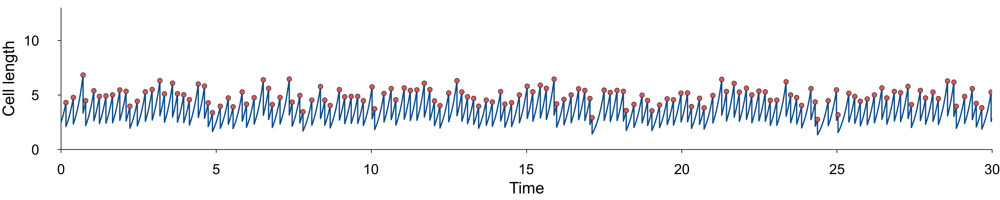

In [28]:
p_traj_sim = plot(; size=(1500,300), xlim=(0,30), ylim=(0,15), xtick=collect(0:5:40), ytick=collect(0:5:15), bottommargin=12Plots.mm,  leftmargin=9Plots.mm, xlabel="Time", ylabel="Cell length")
plot!(p_traj_sim, tsim, Lsim, grid=false, legend=false, lw=2, lc=:dodgerblue4, size=(1500,300), ylim=(0, 13), tickfontsize=14, ytick=[0,5,10])
scatter!(tsim[isdiv_sim], Lsim[isdiv_sim])
p_traj_sim

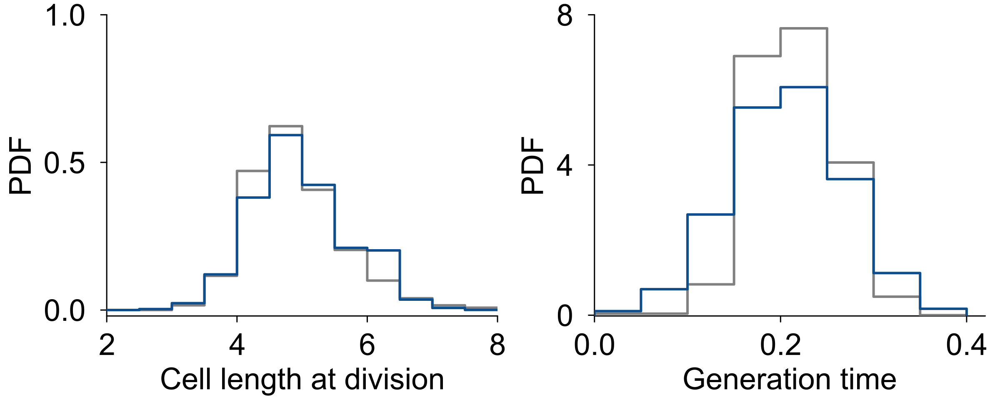

In [29]:
p_stats_a = plot()
stephist!( p_stats_a, vcat( [Lobs_[i][isdiv_[i]] for i in eachindex(Lobs_)]... ), normalize=:pdf,
         xlim=(2,8), xtick=[0,2,4,6,8],ylim=(-0.02,1),ytick=collect(0:0.5:2),bins=collect(2:0.5:8),
         ylabel="PDF", xlabel="Cell length at division")
stephist!( p_stats_a, Lsim[isdiv_sim], normalize=:pdf, lc=:dodgerblue4,  bins=collect(2:0.5:8))


p_stats_b = plot()
stephist!( p_stats_b, vcat( diff.([tobs_[i][isdiv_[i]] for i in eachindex(tobs_)]) ... ), normalize=:pdf,
        xlim=(0,0.42), xtick=collect(0:0.2:0.4),ylim=(-0.02,8),ytick=[0,4,8], bins=collect(0:0.05:0.4),
        ylabel="PDF", xlabel="Generation time" )
stephist!( p_stats_b, diff(tsim[isdiv_sim]), normalize=:pdf, lc=:dodgerblue4, bins=collect(0:0.05:0.4))

ll = @layout [a b]
plot(p_stats_a, p_stats_b, layout=ll, size=(800, 320), bottommargin=7Plots.mm,leftmargin=bottommargin=5Plots.mm)

### Looking at joint probability

In [31]:
using StatsBase
hedges = collect(2:0.5:7.5);
hbins = 0.5*( hedges[1:end-1] + hedges[2:end] )
dhedges = mean( diff(hedges) );
h1_sim = fit(Histogram, Lsim[isdiv_sim], hedges)
h2_sim = fit(Histogram, (Lsim[isdiv_sim][1:end-1], Lsim[isdiv_sim][2:end]), (hedges,hedges));

h1_obs = fit(Histogram, vcat( [Lobs_[i][isdiv_[i]] for i in eachindex(Lobs_) ]...), hedges)
h2_obs = fit(Histogram, (vcat( [Lobs_[i][isdiv_[i]][1:end-1] for i in eachindex(Lobs_) ]...), vcat( [Lobs_[i][isdiv_[i]][2:end] for i in eachindex(Lobs_) ]...) ), (hedges,hedges));


In [32]:
# sim
h1_sim_normalize = h1_sim.weights / sum(h1_sim.weights) / dhedges
h2_sim_normalize = h2_sim.weights / sum(h2_sim.weights) / dhedges^2

svd_h1_sim = svd(h1_sim_normalize * h1_sim_normalize');
svd_h2_sim = svd(h2_sim_normalize);

# obs
h1_obs_normalize = h1_obs.weights / sum(h1_obs.weights) / dhedges
h2_obs_normalize = h2_obs.weights / sum(h2_obs.weights) / dhedges^2

svd_h1_obs = svd(h1_obs_normalize * h1_obs_normalize');
svd_h2_obs = svd(h2_obs_normalize);

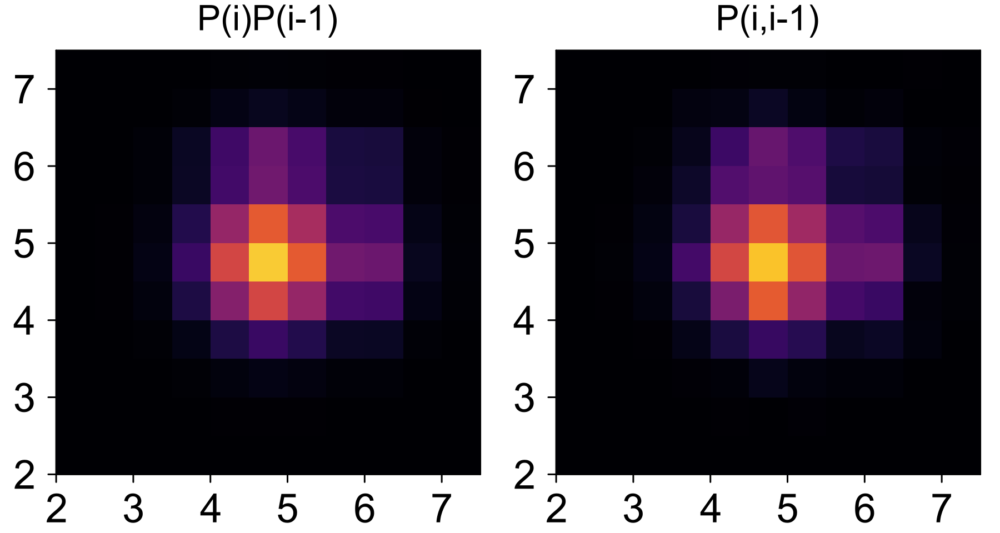

In [33]:
p_h1_sim = plot(; aspect_ratio=1, framestyle=:box, xlim=(2,7.5), ylim=(2,7.5), xtick=collect(2:8), ytick=collect(2:8), title="P(i)P(i-1)" )
heatmap!( p_h1_sim, hbins, hbins, h1_sim_normalize * h1_sim_normalize', clim=(0,0.4)) 

p_h2_sim = plot(; aspect_ratio=1, framestyle=:box, xlim=(2,7.5), ylim=(2,7.5), xtick=collect(2:8), ytick=collect(2:8), title="P(i,i-1)" )
heatmap!( p_h2_sim, hbins, hbins, h2_sim_normalize, clim=(0,0.4)) 

plot(p_h1_sim, p_h2_sim, layout = ll, size=(600,320))

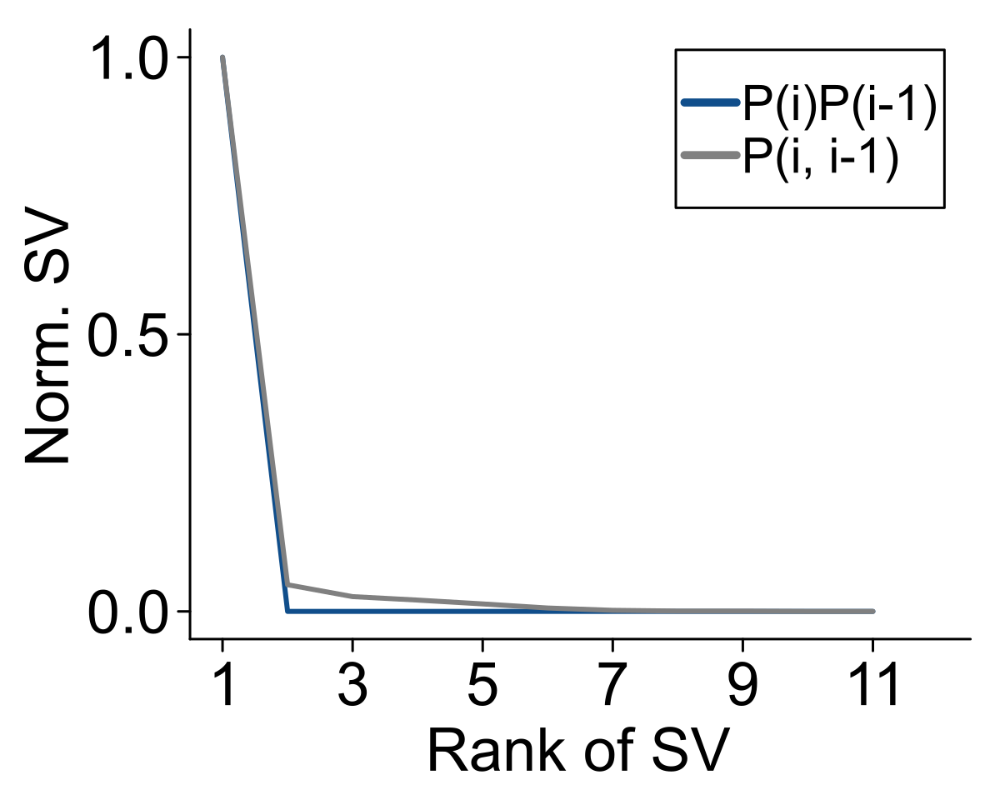

In [34]:
p_S_sim = plot(; xlim=[0.5,12.5], ylim=[-0.05,1.05], ytick=[0,0.5,1], xtick=collect(1:2:13), xlabel="Rank of SV", ylabel = "Norm. SV", legend=true)
plot!( p_S_sim, svd_h1_sim.S ./ svd_h1_sim.S[1], lc=:dodgerblue4, label="P(i)P(i-1)" )
plot!( p_S_sim, svd_h2_sim.S ./ svd_h2_sim.S[1],  label="P(i, i-1)" )


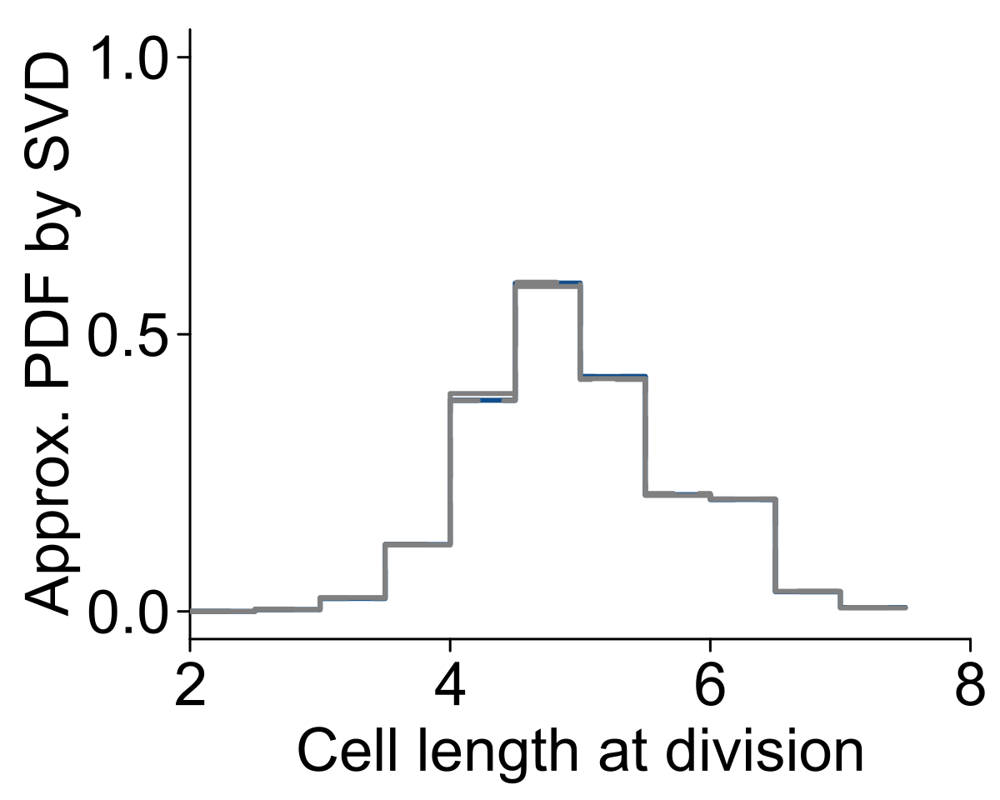

In [35]:
yU_h1_sim = svd_h1_sim.U[:,1] * sqrt(svd_h1_sim.S[1])
yV_h1_sim = svd_h1_sim.V[:,1] * sqrt(svd_h1_sim.S[1])

yU_h2_sim = svd_h2_sim.U[:,1] * sqrt(svd_h2_sim.S[1])
yV_h2_sim = svd_h2_sim.V[:,1] * sqrt(svd_h2_sim.S[1])

function plot_histogram!( pp, _hedges::Vector{T}, _y::Vector{T}; plot_args...) where T
    _index_edges = vcat([[i,i] for i in 1:length(_hedges)]...);
    _index_y = vcat([[i,i] for i in 1:length(_y)]...);
    plot!(pp, _hedges[_index_edges[2:end-1]], _y[_index_y]; plot_args...)
    nothing
end

p_UV_sim = plot(; ylim=(-0.05,1.05), xlim=(2,8), xtick=collect(2:2:8), ytick=collect(0:0.5:1), xlabel="Cell length at division", ylabel="Approx. PDF by SVD")
plot_histogram!(p_UV_sim, hedges, abs.(yU_h1_sim); lc=:dodgerblue4)
plot_histogram!(p_UV_sim, hedges, abs.(yV_h1_sim); ls=:dash, lc=:dodgerblue4)
plot_histogram!(p_UV_sim, hedges, abs.(yU_h2_sim))
plot_histogram!(p_UV_sim, hedges, abs.(yV_h2_sim); ls=:dash)
p_UV_sim

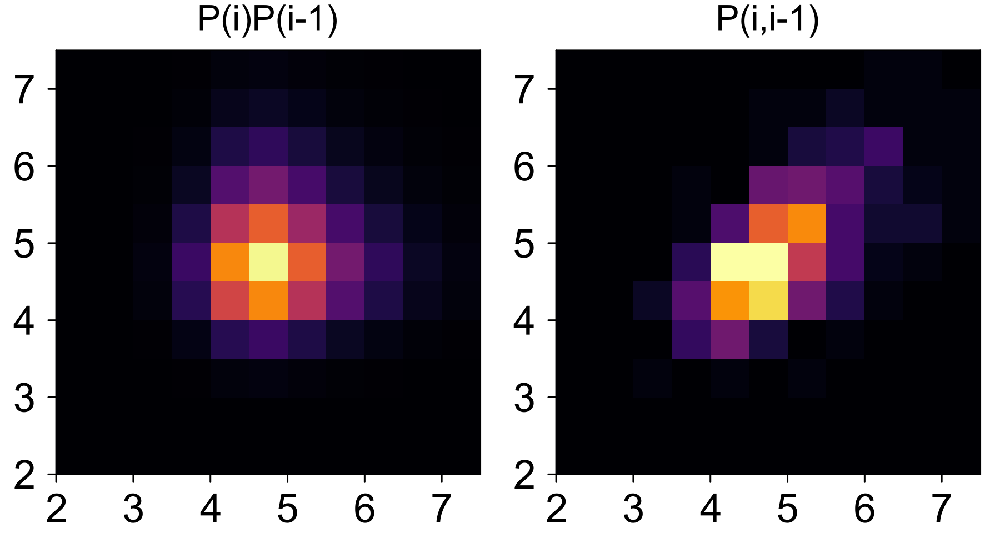

In [37]:
p_h1_obs = plot(; aspect_ratio=1, framestyle=:box, xlim=(2,7.5), ylim=(2,7.5), xtick=collect(2:8), ytick=collect(2:8), title="P(i)P(i-1)" )
heatmap!( p_h1_obs, hbins, hbins, h1_obs_normalize * h1_obs_normalize', clim=(0,0.4)) 

p_h2_obs = plot(; aspect_ratio=1, framestyle=:box, xlim=(2,7.5), ylim=(2,7.5), xtick=collect(2:8), ytick=collect(2:8), title="P(i,i-1)" )
heatmap!( p_h2_obs, hbins, hbins, h2_obs_normalize, clim=(0,0.4)) 

plot(p_h1_obs, p_h2_obs, layout = ll, size=(600,320))

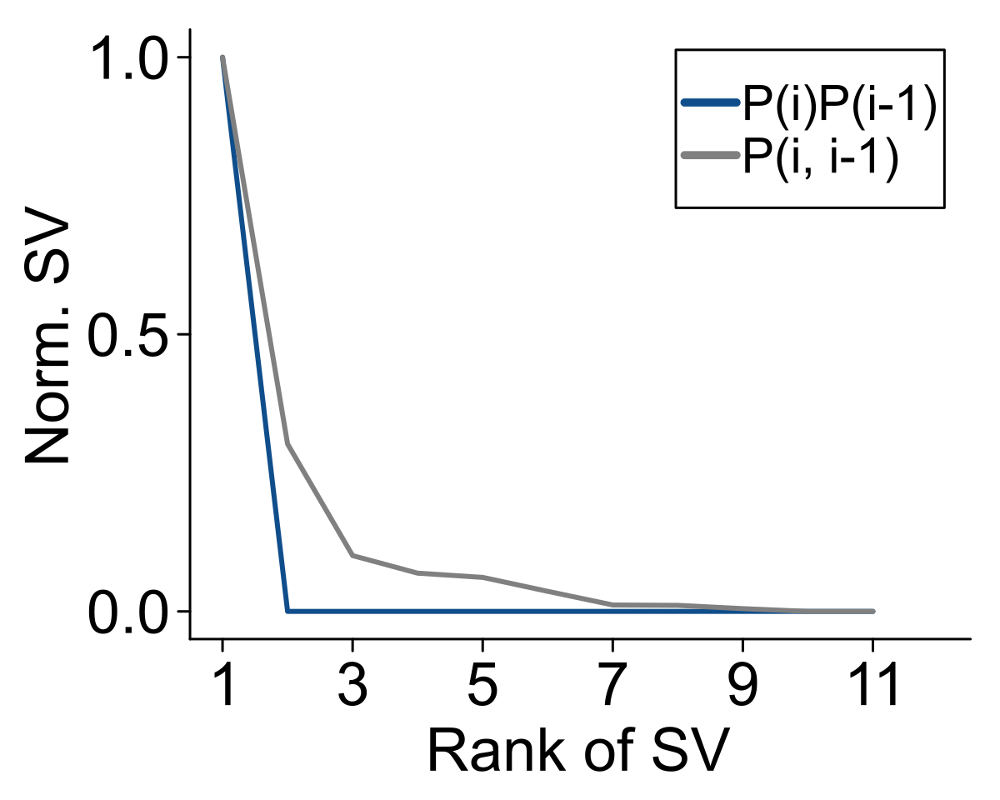

In [38]:
p_S_obs = plot(; xlim=[0.5,12.5], ylim=[-0.05,1.05], ytick=[0,0.5,1], xtick=collect(1:2:13), xlabel="Rank of SV", ylabel = "Norm. SV", legend=true)
plot!( p_S_obs, svd_h1_obs.S ./ svd_h1_obs.S[1], lc=:dodgerblue4, label="P(i)P(i-1)" )
plot!( p_S_obs, svd_h2_obs.S ./ svd_h2_obs.S[1],  label="P(i, i-1)" )


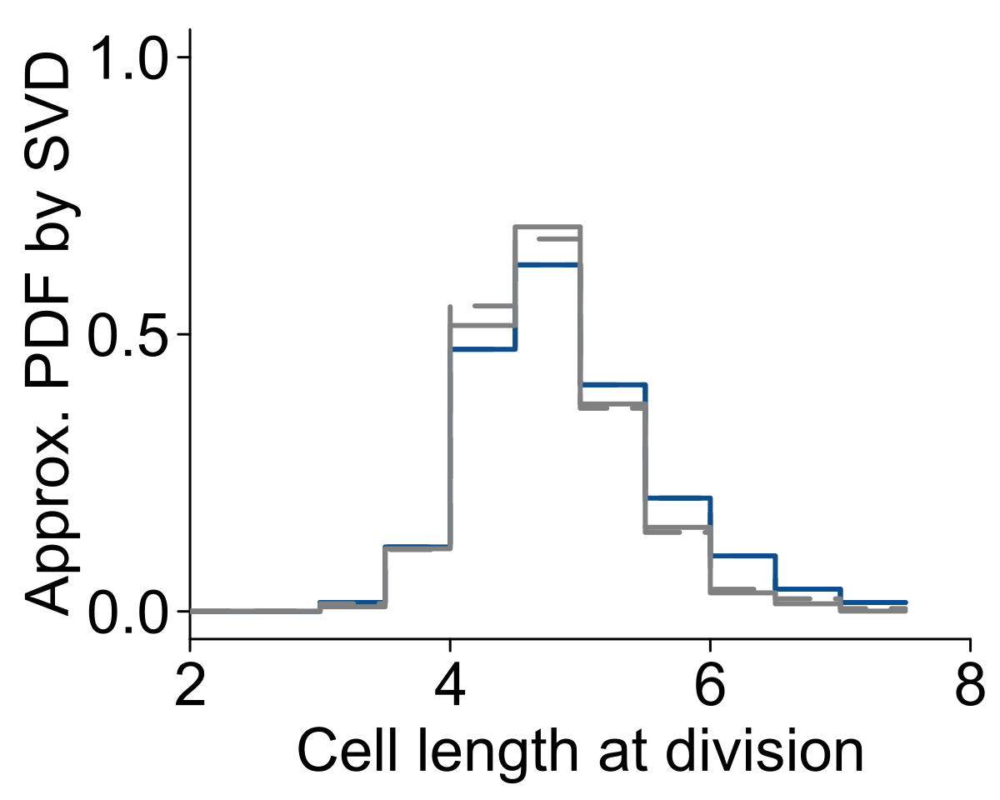

In [39]:
yU_h1_obs = svd_h1_obs.U[:,1] * sqrt(svd_h1_obs.S[1])
yV_h1_obs = svd_h1_obs.V[:,1] * sqrt(svd_h1_obs.S[1])

yU_h2_obs = svd_h2_obs.U[:,1] * sqrt(svd_h2_obs.S[1])
yV_h2_obs = svd_h2_obs.V[:,1] * sqrt(svd_h2_obs.S[1])

p_UV_obs = plot(; ylim=(-0.05,1.05), xlim=(2,8), xtick=collect(2:2:8), ytick=collect(0:0.5:1), xlabel="Cell length at division", ylabel="Approx. PDF by SVD")
plot_histogram!(p_UV_obs, hedges, abs.(yU_h1_obs); lc=:dodgerblue4)
plot_histogram!(p_UV_obs, hedges, abs.(yV_h1_obs); ls=:dash, lc=:dodgerblue4)
plot_histogram!(p_UV_obs, hedges, abs.(yU_h2_obs))
plot_histogram!(p_UV_obs, hedges, abs.(yV_h2_obs); ls=:dash)
p_UV_obs

### multiple sparsity

In [189]:
coeffs_multisparsity, num_sparsity = sparse_optimization_multisparsity(Θ, Θdiv, vcat(dtobs_...); EPSILON=1E-7, MAX_ITERS=40);

itr=1: -806.2976708195274


itr=2: -806.3385943369261


itr=3: -805.8106504340406


itr=4: -806.0645472412025


itr=5: -805.8690407085472


itr=6: -805.5576699340681


... (18 outputs left out)

itr=25: -804.1548296499133
itr=1: -802.8809877051716
itr=2: -804.5387374691504
itr=3: -804.3624432369287
itr=4: -804.2690050809044


itr=5: -804.2188832113212
itr=6: -804.1913200563955
itr=7: -804.1758987160789
itr=8: -804.1670363928555
itr=9: -804.1618728213035
itr=10: -804.1588851945388


itr=11: -804.1571456852929
itr=12: -804.156060748542
itr=13: -804.1555137648057
itr=14: -804.1551779139741
itr=15: -804.1549754666202
itr=16: -804.154874012979


itr=17: -804.1547948448325
itr=1: -800.3266212069941
itr=2: -802.0363775943855
itr=3: -802.0140987636971
itr=4: -802.0106748138926
itr=5: -802.0100232738858
itr=6: -802.0098581405401
itr=7: -802.0098581405401


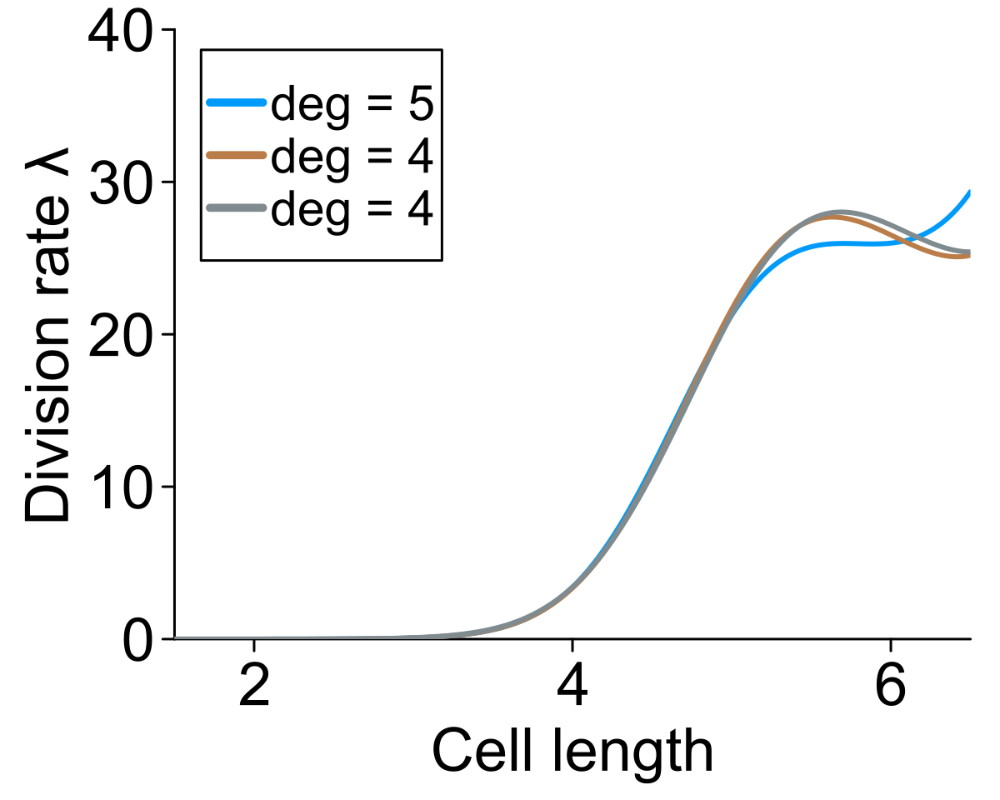

In [203]:
uu = collect(1.5:0.01:10.5);
p2 = plot(;legend=true, ylim=(0,40), ytick=collect(0:10:40), xlim=(1.5, 6.5), xtick=collect(2:2:10))
linecolor_ = palette(:default, length(Lobs_) )
for i = 1:length(coeffs_multisparsity)
    logλ_sparse = rec_ortho_bases(uu, Σ, coeffs_multisparsity[i]);
    formatted_label = @sprintf("deg = %d", num_sparsity[i])
    plot!(p2, uu, exp.(logλ_sparse), label = formatted_label, lw=2, lc=linecolor_[i], ylabel="Division rate λ", xlabel="Cell length", legend=:topleft)
end
p2

### L1 saprse optimization

In [149]:
_, coeff_L1 = sparse_optimization_L1(Θ, Θdiv, vcat(dtobs_...); lam = 1.0);

In [150]:
coeff_L1

11-element Vector{Float64}:
 -0.7272082219051594
  2.560360020868021
 -0.6428522737871217
 -0.22212690419423572
  0.31969327297068767
 -0.041382960704867626
 -0.12519667278300362
  0.0875406198703992
 -0.009620033004568242
 -9.622469504258523e-7
 -1.0855413469609852e-8

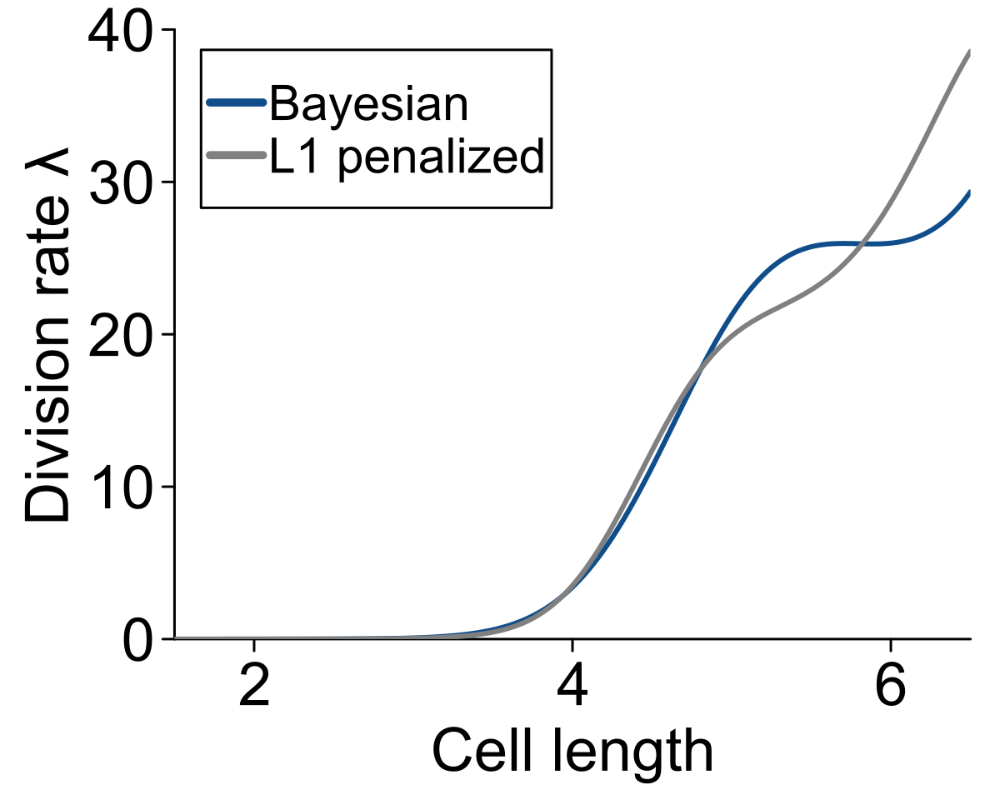

In [151]:
# (optional)
COEFF_TRESHOLD = 0.02
coeff_L1[abs.(coeff_L1) .< COEFF_TRESHOLD] .= 0.0

uu = collect(1.5:0.01:10.5);
logλ_sparse = rec_ortho_bases(uu, Σ, coeffs_sparse);

p2 = plot(;legend=true, ylim=(0,40), ytick=collect(0:10:40), xlim=(1.5, 6.5), xtick=collect(2:2:10))
plot!(p2, uu, exp.(logλ_sparse),label="Bayesian", lw=2, lc=:dodgerblue4,  ylabel="Division rate λ", xlabel="Cell length")

logλ_sparse = rec_ortho_bases(uu, Σ, coeff_L1);
plot!(p2, uu, exp.(logλ_sparse), label="L1 penalized", lw=2,  ylabel="Division rate λ", xlabel="Cell length")
